# 候选重排：IR + Raman + NMR

按候选结构与输入谱图的一致性进行排序。

openSpec 模型通过 Vib2Mol 编码谱通道。生成使用 beam search 和分子匹配分数；检索比较嵌入，候选重排使用匹配头。

本教程读取保存的预测，解释输入输出字段，并评估结果。最后给出在新数据集上运行模型的命令。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('spectroscopy.reranking.hc')
print('Task:', evidence['task'])
print('Examples:', len(evidence['examples']))

Task: spectroscopy.reranking.hc
Examples: 3


## 输入与输出

| Field | Meaning |
| --- | --- |
| `IR / Raman` | 每个可见通道 1024 个强度点，按 400→4000 cm⁻¹ 排列，并采用 checkpoint 的归一化。 |
| `1H / 13C` | 逐原子位移数组（ppm），参考 ID 和归一化必须与 checkpoint 一致。 |
| `candidate structures` | 用于排序的分子候选库。 |

| Field | Meaning |
| --- | --- |
| `ranking` | 候选结构 ID，以及相似度或 ITM 正类分数。 |
| `recall / MRR` | 排序指标、候选池大小及样本来源构成。 |

查看下面的示例记录。长数组显示长度与前几个数值，下载 JSON 可获取完整数组。

In [2]:
for example in evidence['examples'][:3]:
    print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "sample_id": "ZINCV2-ZINC000646741030",
  "input": {
    "ir": {
      "length": 1024,
      "first_values": [
        0.15220004320144653,
        0.190755695104599,
        0.2037702202796936,
        0.1804114133119583,
        0.1386023461818695,
        0.10100352019071579,
        0.07402963191270828,
        0.05563068017363548
      ]
    },
    "raman": {
      "length": 1024,
      "first_values": [
        0.04284051060676575,
        0.0596662312746048,
        0.059223152697086334,
        0.04435715824365616,
        0.03070877492427826,
        0.02493642456829548,
        0.021241741254925728,
        0.01620982028543949
      ]
    },
    "nmr_h_shifts_ppm": {
      "length": 13,
      "first_values": [
        0.40027499198913574,
        0.70107501745224,
        3.4114749431610107,
        3.4215750694274902,
        3.694974899291992,
        3.7509748935699463,
        3.7543749809265137,
        3.904474973678589
      ]
    },
    "nmr_c_shifts_ppm": {
     

## 评估预测

生成报告 top-k 准确率，排序报告 Recall@k 与 MRR。

表格给出每次运行的数据集与指标。后续代码从绘图使用的预测值重新计算汇总结果。

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded sample | recorded model | recall_at_1 | 1 |
| recorded sample | recorded model | recall_at_5 | 1 |
| recorded sample | recorded model | recall_at_10 | 1 |
| recorded sample | recorded model | mrr | 1 |
| recorded sample | recorded model | queries | 16 |
| recorded sample | recorded model | candidate_pool | 16 |
| recorded sample | recorded model | unique_candidates | 16 |
| recorded sample | recorded model | tie_policy | stable_candidate_order |
| recorded sample | recorded model | top_1_hit_rate | 1 |


{
  "scope": "Saved model outputs are shown directly; aggregate metrics are in the run table.",
  "recorded_runs": 1,
  "real_examples": 3
}


## 查看结果图

按谱相似度排序的分子候选。

比较预测与参考，查看返回的结构或峰位置。图由上方读取的记录直接生成。

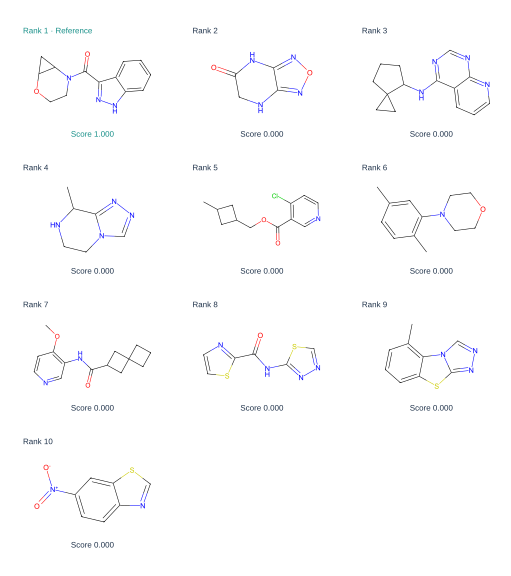

In [4]:
import matplotlib.pyplot as plt
for example_index in range(1):
    figure = render('spectroscopy.reranking.hc', evidence, example_index=example_index)
    image = io.StringIO()
    figure.savefig(image, format='svg', metadata={'Date': None})
    display(SVG(image.getvalue()))
    plt.close(figure)

## 运行模型

按任务指南配置环境和权重，在 benchmark runner 中选择本任务，即可评估自己的数据集。

```bash
python -m openmolspec_bench run --workspace /path/to/OpenMolSpec \
  --tasks spectroscopy.reranking.hc --limit 8 --output results/spectroscopy-reranking-hc.json
```

[Task](../tasks/spectroscopy-reranking-hc.md) · [Quick start](../quickstart.md)



## 参考文献

- OpenMolSpec contributors. openSpec models and benchmark training workflows. Source archive, v1.0 (2026). [Source](https://github.com/jiaqingxie/openmolspec-studio-frontend/tree/release/openmolspec-v1/documentation/assets/benchmarks)
- OpenMolSpec contributors. OpenMolSpec: Chemical spectroscopy datasets, models and learning workflows. Software release v1.0 (2026). [Source](https://github.com/jiaqingxie/openmolspec-studio-frontend/releases/tag/v1.0)
- Yuan, M., Zou, Z. & Hu, W. QMe14S, A Comprehensive and Efficient Spectral Dataset for Small Organic Molecules. arXiv:2501.18876 (2025). [Source](https://arxiv.org/abs/2501.18876)
- Zou, Z., Zhang, Y., Liang, L., Wei, M., Leng, J., Jiang, J., Luo, Y. & Hu, W. A deep learning model for predicting selected organic molecular spectra. Nature Computational Science 3, 957–964 (2023). doi:10.1038/s43588-023-00550-y. [Source](https://www.nature.com/articles/s43588-023-00550-y)
